# Interferometría con Sentinel‑1: desplazamiento en el Valle de Aburrá entre el 2 y el 14 de agosto de 2026

Este cuaderno reproduce el ejercicio del acto «06 · InSAR» de la presentación `presentaciones/insar_sentinel1.html`: lleva dos imágenes de radar de fechas distintas hasta un mapa de desplazamiento del terreno en la línea de vista, y dibuja las figuras con que se interpreta el resultado.

Los datos de entrada son:

- `S1C_IW_SLC__1SDV_20260802T105000_…_65E3.SAFE.zip` y `S1C_IW_SLC__1SDV_20260814T105000_…_9190.SAFE.zip`: dos imágenes Sentinel‑1C, modo IW, producto SLC, de la órbita relativa 142 (programa Copernicus).
- Modelo de elevación SRTM de 1 segundo de arco y órbitas precisas: SNAP los descarga cuando los necesita.

Los programas son SNAP 14 (se usa su ejecutor por línea de comandos, `gpt`) y SNAPHU 2.0.7.

Las imágenes pesan 7,6 GB cada una; por eso no están en la carpeta `data/` del repositorio, sino en la carpeta que se indica en la sección 1. Cada paso se salta si su resultado ya existe: la primera ejecución completa tarda unos 10 minutos y ocupa 7 GB; las siguientes, segundos.

## 1. Preparación: rutas, programas y una función para ejecutar SNAP

Se definen las carpetas de trabajo y la ubicación de los dos programas. La función `snap` ejecuta un operador de SNAP y deja escrito cuánto tardó; si el producto de salida ya existe, no lo repite.

In [1]:
from pathlib import Path
import json, os, re, subprocess, time, zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CARPETA = Path.home() / "Desktop" / "InSar"            # donde están las dos imágenes
PROCESO = CARPETA / "proceso"                          # productos intermedios y finales
FIGURAS = PROCESO / "figuras"
GPT = Path("/Applications/esa-snap/bin/gpt")           # en Windows: C:/Program Files/esa-snap/bin/gpt.exe
SNAPHU = CARPETA / "herramientas" / "snaphu-v2.0.7" / "bin" / "snaphu"
GUARDAR_FIGURAS = False                                # True para volver a escribir los .jpg en FIGURAS

FECHA_1 = next(CARPETA.glob("S1C_IW_SLC__1SDV_20260802*.zip"))   # referencia: la más antigua
FECHA_2 = next(CARPETA.glob("S1C_IW_SLC__1SDV_20260814*.zip"))
PROCESO.mkdir(exist_ok=True); FIGURAS.mkdir(exist_ok=True)
print(FECHA_1.name, FECHA_2.name, sep="\n")

S1C_IW_SLC__1SDV_20260802T105000_20260802T105027_008815_0117B6_65E3.SAFE.zip
S1C_IW_SLC__1SDV_20260814T105000_20260814T105027_008990_011D78_9190.SAFE.zip


In [2]:
def snap(operador, salida, fuentes, clave="source", **parametros):
    """Ejecuta un operador de SNAP. No repite el paso si el producto de salida ya existe."""
    salida = PROCESO / salida
    if salida.exists():
        print(f"{operador}: ya existe {salida.name}"); return salida
    orden = [str(GPT), operador] + [f"-P{k}={v}" for k, v in parametros.items()] + ["-t", str(salida)]
    fuentes = [str(f) for f in fuentes]
    orden += [f"-S{clave}={fuentes[0]}"] if len(fuentes) == 1 else fuentes
    inicio = time.time()
    r = subprocess.run(orden, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-1500:])
    print(f"{operador}: {salida.name} en {time.time() - inicio:.0f} s"); return salida

## 2. Revisión del par: ¿las dos imágenes se pueden comparar?

Dos imágenes sirven para interferometría si se tomaron desde la misma órbita relativa, con la misma dirección de paso y en el mismo modo. Esos datos están en el archivo `manifest.safe` de cada producto.

In [3]:
def ficha(producto):
    with zipfile.ZipFile(producto) as z:
        m = z.read(next(n for n in z.namelist() if n.endswith("manifest.safe"))).decode()
    dato = lambda patron: re.search(patron, m).group(1)
    return {"producto": producto.name[:32], "inicio": dato(r"<safe:startTime>([^<]+)"), "dirección": dato(r"<s1:pass>([A-Z]+)"),
            "órbita relativa": dato(r'<safe:relativeOrbitNumber type="start">(\d+)'), "modo": dato(r"<s1sarl1:mode>([A-Z]+)"),
            "polarizaciones": ", ".join(re.findall(r"<s1sarl1:transmitterReceiverPolarisation>([A-Z]+)", m))}

pd.DataFrame([ficha(FECHA_1), ficha(FECHA_2)], index=["fecha 1", "fecha 2"]).T

,fecha 1,fecha 2
producto,S1C_IW_SLC__1SDV_20260802T105000,S1C_IW_SLC__1SDV_20260814T105000
inicio,2026-08-02T10:50:00.112275,2026-08-14T10:50:00.856519
dirección,DESCENDING,DESCENDING
órbita relativa,142,142
modo,IW,IW
polarizaciones,"VV, VH","VV, VH"


## 3. Alinear el par

Antes de comparar las fases hay que quedarse con la zona de interés, corregir la posición del satélite y hacer que cada píxel de la segunda fecha caiga sobre el mismo terreno que en la primera.

### 3.1 Dividir: una subfranja, una polarización y tres ráfagas

El modo IW cubre 250 km con tres subfranjas, cada una tomada por ráfagas. Se conserva la subfranja IW1, la polarización VV y las ráfagas 3 a 5, que cubren el Valle de Aburrá.

In [4]:
recorte = dict(subswath="IW1", selectedPolarisations="VV", firstBurstIndex=3, lastBurstIndex=5)
f1 = snap("TOPSAR-Split", "f1_split.dim", [FECHA_1], **recorte)
f2 = snap("TOPSAR-Split", "f2_split.dim", [FECHA_2], **recorte)

TOPSAR-Split: ya existe f1_split.dim
TOPSAR-Split: ya existe f2_split.dim


### 3.2 Aplicar las órbitas precisas

La línea base y la fase de tierra plana se calculan con la posición del satélite. La órbita que trae el producto es aproximada; la precisa se publica unos 20 días después de la toma.

In [5]:
orbita = {"orbitType": "Sentinel Precise (Auto Download)", "continueOnFail": "false"}
f1o = snap("Apply-Orbit-File", "f1_split_Orb.dim", [f1], **orbita)
f2o = snap("Apply-Orbit-File", "f2_split_Orb.dim", [f2], **orbita)

Apply-Orbit-File: ya existe f1_split_Orb.dim
Apply-Orbit-File: ya existe f2_split_Orb.dim


### 3.3 Corregistrar las dos fechas

El corregistro alinea la fecha 2 sobre la fecha 1 con ayuda de las órbitas y del modelo de elevación. Un segundo operador, *Enhanced Spectral Diversity*, afina el alineado en la dirección de avance.

In [6]:
pila = snap("Back-Geocoding", "par_Orb_Stack.dim", [f1o, f2o], demName="SRTM 1Sec HGT")
pila = snap("Enhanced-Spectral-Diversity", "par_Orb_Stack_esd.dim", [pila])

Back-Geocoding: ya existe par_Orb_Stack.dim
Enhanced-Spectral-Diversity: ya existe par_Orb_Stack_esd.dim


## 4. Formar y limpiar el interferograma

### 4.1 Interferograma y coherencia

Se multiplica la imagen de la fecha 1 por el conjugado de la fecha 2: la fase del resultado es la diferencia de fases. En el mismo paso se resta la fase de tierra plana y se estima la coherencia.

In [7]:
ifg = snap("Interferogram", "par_ifg.dim", [pila], clave="sourceProduct", subtractFlatEarthPhase="true", includeCoherence="true", cohWinRg=10, cohWinAz=3)

Interferogram: ya existe par_ifg.dim


SNAP deja en los metadatos la geometría del par. Con ella se comprueba la fórmula de la altura de ambigüedad de la presentación: longitud de onda por distancia por seno de la incidencia, dividido por dos veces la línea base perpendicular.

In [8]:
meta = ifg.read_text(errors="ignore")
dato = lambda nombre, cual=0: float(re.findall(rf'name="{nombre}"[^>]*>([^<]+)', meta)[cual])
b_perp, h_amb, dias = abs(dato("Perp Baseline", 1)), abs(dato("Height of Ambiguity", 1)), abs(dato("Temp Baseline", 1))
lam = 299792458 / (dato("radar_frequency") * 1e6)
inc = np.radians((dato("incidence_near") + dato("incidence_far")) / 2)
R = dato("slant_range_to_first_pixel") + dato("range_spacing") * dato("num_samples_per_line") / 2
print(f"Línea base perpendicular: {b_perp:.1f} m · separación temporal: {dias:.0f} días")
print(f"Altura de ambigüedad según SNAP: {h_amb:.0f} m · según la fórmula: {lam * R * np.sin(inc) / (2 * b_perp):.0f} m")
print(f"Ancho de banda: {dato('range_bandwidth')} MHz · resolución en distancia: {299792458 / (2 * dato('range_bandwidth') * 1e6):.2f} m")

Línea base perpendicular: 53.1 m · separación temporal: 12 días
Altura de ambigüedad según SNAP: 240 m · según la fórmula: 240 m
Ancho de banda: 56.5 MHz · resolución en distancia: 2.65 m


### 4.2 Unir las ráfagas

Las ráfagas se unen en una imagen continua.

In [9]:
deb = snap("TOPSAR-Deburst", "par_ifg_deb.dim", [ifg])

TOPSAR-Deburst: ya existe par_ifg_deb.dim


### 4.3 Restar la fase del relieve

El relieve deja una franja por cada altura de ambigüedad. Se calcula con el modelo de elevación y se resta, para que no se confunda con movimiento. SNAP también permite restarlo al formar el interferograma (casilla *Subtract topographic phase*); aquí se hace en un paso aparte y una sola vez.

In [10]:
sin_relieve = snap("TopoPhaseRemoval", "par_ifg_deb_dinsar.dim", [deb], clave="sourceProduct", demName="SRTM 1Sec HGT")

TopoPhaseRemoval: ya existe par_ifg_deb_dinsar.dim


### 4.4 Promediar píxeles vecinos (multilook)

Se promedian los números complejos de 8 píxeles en rango y 2 en azimut, antes de calcular la fase. El ruido baja y el píxel queda de unos 33 por 28 m sobre terreno horizontal. Los 30 m del mapa final se eligen después, al geocodificar.

In [11]:
ml = snap("Multilook", "par_ifg_deb_dinsar_ML.dim", [sin_relieve], nRgLooks=8, nAzLooks=2)

Multilook: ya existe par_ifg_deb_dinsar_ML.dim


### 4.5 Filtrar la fase

El filtro de Goldstein reduce el ruido de la fase para que el desenrollado cometa menos errores. No recupera las zonas sin coherencia.

In [12]:
flt = snap("GoldsteinPhaseFiltering", "par_ifg_deb_dinsar_ML_flt.dim", [ml], clave="sourceProduct", alpha=1.0, FFTSizeString=64, windowSizeString=3, useCoherenceMask="false")

GoldsteinPhaseFiltering: ya existe par_ifg_deb_dinsar_ML_flt.dim


## 5. Obtener el desplazamiento

### 5.1 Exportar para SNAPHU y revisar `snaphu.conf`

SNAP prepara los archivos que necesita SNAPHU. En este ejercicio, SNAP 14.0.0 dejó vacío el nombre del archivo de coherencia (línea `CORRFILE`); la celda lo corrige si hace falta.

In [13]:
destino = PROCESO / "snaphu"
if not list(destino.glob("*/snaphu.conf")):
    destino.mkdir(exist_ok=True)
    r = subprocess.run([str(GPT), "SnaphuExport", f"-Ssource={flt}", f"-PtargetFolder={destino}", "-PstatCostMode=DEFO", "-PinitMethod=MCF",
                        "-PnumberOfTileRows=1", "-PnumberOfTileCols=1", "-t", str(destino), "-f", "Snaphu"], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-1500:]
carpeta_snaphu = next(destino.glob("*/snaphu.conf")).parent
conf = (carpeta_snaphu / "snaphu.conf").read_text().splitlines()
coherencia = next(carpeta_snaphu.glob("coh_*.snaphu.img")).name
conf = [f"CORRFILE        {coherencia}" if re.match(r"CORRFILE\s", linea + " ") and coherencia not in linea else linea for linea in conf]
(carpeta_snaphu / "snaphu.conf").write_text("\n".join(conf) + "\n")
orden = next(l for l in conf if "snaphu -f" in l).lstrip("# ").split()
print("CORRFILE:", coherencia); print("Orden:", " ".join(orden))

CORRFILE: coh_IW1_VV_02Aug2026_14Aug2026.snaphu.img
Orden: snaphu -f snaphu.conf Phase_ifg_VV_02Aug2026_14Aug2026.snaphu.img 2648


### 5.2 Desenrollar con SNAPHU

SNAPHU avanza de un píxel a su vecino y suma las vueltas completas que faltan. En este recorte tarda unos 5 minutos.

In [14]:
if not list(carpeta_snaphu.glob("UnwPhase*.snaphu.img")):
    inicio = time.time()
    r = subprocess.run([str(SNAPHU)] + orden[1:], cwd=carpeta_snaphu, capture_output=True, text=True)
    assert r.returncode == 0, (r.stdout + r.stderr)[-1500:]
    print(f"SNAPHU: {time.time() - inicio:.0f} s")
desenrollada = next(carpeta_snaphu.glob("UnwPhase*.snaphu.hdr")); print(desenrollada.name)

UnwPhase_ifg_VV_02Aug2026_14Aug2026.snaphu.hdr


Una comprobación sencilla: al volver a enrollar el resultado debe obtenerse la misma fase que entró a SNAPHU. Si coincide, el programa solo añadió vueltas completas; no prueba que el número de vueltas sea el correcto.

In [15]:
def binario(patron):
    f = next(carpeta_snaphu.glob(patron)); h = f.with_suffix(".hdr").read_text()
    n = lambda k: int(re.search(rf"{k}\s*=\s*(\d+)", h).group(1))
    return np.fromfile(f, dtype="<f4").reshape(n("lines"), n("samples"))

entrada, salida = binario("Phase*.snaphu.img"), binario("UnwPhase*.snaphu.img")
diferencia = np.abs(np.angle(np.exp(1j * (salida.astype(float) - entrada))))
print(f"Mayor diferencia al volver a enrollar: {diferencia.max():.1e} rad · píxeles con más de 0,001 rad: {(diferencia > 1e-3).sum()}")
vueltas = np.round((salida - entrada) / (2 * np.pi))
print(f"Vueltas añadidas: de {vueltas.min():.0f} a {vueltas.max():.0f}")

Mayor diferencia al volver a enrollar: 2.4e-05 rad · píxeles con más de 0,001 rad: 0


Vueltas añadidas: de -5 a 4


### 5.3 Importar, convertir la fase en desplazamiento y geocodificar

La fase desenrollada se convierte en metros a lo largo de la línea de vista y se lleva a coordenadas de mapa. Con el desplazamiento se guarda la elevación del terreno, que se usa en la interpretación. La coherencia y la fase se geocodifican con los mismos parámetros.

In [16]:
unw = snap("SnaphuImport", "par_ifg_deb_dinsar_ML_flt_unw.dim", [flt, desenrollada])
dsp = snap("PhaseToDisplacement", "par_ifg_deb_dinsar_ML_flt_unw_dsp.dim", [unw])
mapa = dict(demName="SRTM 1Sec HGT", pixelSpacingInMeter=30.0)
dsp_tc = snap("Terrain-Correction", "par_ifg_deb_dinsar_ML_flt_unw_dsp_TC_dem.dim", [dsp], saveDEM="true", **mapa)
bandas = "coh_IW1_VV_02Aug2026_14Aug2026,Phase_ifg_VV_02Aug2026_14Aug2026"
flt_tc = snap("Terrain-Correction", "par_ifg_deb_dinsar_ML_flt_TC.dim", [flt], imgResamplingMethod="NEAREST_NEIGHBOUR", sourceBands=bandas, **mapa)

SnaphuImport: ya existe par_ifg_deb_dinsar_ML_flt_unw.dim


PhaseToDisplacement: ya existe par_ifg_deb_dinsar_ML_flt_unw_dsp.dim
Terrain-Correction: ya existe par_ifg_deb_dinsar_ML_flt_unw_dsp_TC_dem.dim
Terrain-Correction: ya existe par_ifg_deb_dinsar_ML_flt_TC.dim


## 6. Lectura del resultado

### 6.1 Lectura de los productos y zona de referencia

Los productos de SNAP guardan cada banda como una matriz de números reales. El desplazamiento es relativo: se toma como cero la mediana de los píxeles con coherencia mayor que 0,4 dentro del rectángulo de Medellín (latitud 6,19° a 6,30° N; longitud 75,61° a 75,54° O). Todas las cifras se calculan sobre el mapa geocodificado y solo con píxeles que tienen dato: se excluyen los que valen cero, que es el valor sin dato de SNAP. La coherencia mayor que 0,4 es un criterio de calidad de la fase, no una validación del desplazamiento. Lo que resulta es un desplazamiento **aparente**: todavía incluye atmósfera, errores del modelo de elevación y ruido.

In [17]:
def leer(producto, clave):
    d = producto.with_suffix(".data"); f = next(x for x in d.glob("*.img") if clave in x.name)
    h = f.with_suffix(".hdr").read_text(); valor = lambda k: re.search(rf"{k}\s*=\s*(\d+)", h).group(1)
    return np.fromfile(f, dtype=">f4" if int(valor("byte order")) else "<f4").reshape(int(valor("lines")), int(valor("samples")))

def transformacion(producto):
    return [float(x) for x in re.search(r"<IMAGE_TO_MODEL_TRANSFORM>([^<]+)", producto.read_text(errors="ignore")).group(1).split(",")]

coh, fase = leer(flt_tc, "coh"), leer(flt_tc, "Phase")
desp, elev = leer(dsp_tc, "displacement"), leer(dsp_tc, "elevation")
t = transformacion(flt_tc); nl, ns = coh.shape
extension = [t[4], t[4] + ns * t[0], t[5] + nl * t[3], t[5]]
LON, LAT = np.meshgrid(t[4] + (np.arange(ns) + .5) * t[0], t[5] + (np.arange(nl) + .5) * t[3])
valido = (coh > 0) & np.isfinite(coh) & np.isfinite(desp) & (desp != 0)

zonas = {"Medellín": (6.19, 6.30, -75.61, -75.54), "Bello y Copacabana": (6.31, 6.37, -75.58, -75.48), "Envigado, Itagüí y Sabaneta": (6.14, 6.19, -75.63, -75.57),
         "Rionegro": (6.12, 6.20, -75.42, -75.34), "Embalse Peñol-Guatapé": (6.24, 6.32, -75.20, -75.13), "Montaña al occidente del valle": (6.20, 6.35, -75.80, -75.70)}
caja = lambda la, lb, loa, lob: (LAT >= la) & (LAT <= lb) & (LON >= loa) & (LON <= lob)
fiable = valido & (coh > 0.4)
referencia = np.median(desp[caja(*zonas["Medellín"]) & fiable])
cm = (desp - referencia) * 100          # centímetros respecto a Medellín; positivo: acercamiento al radar
assert coh.shape == fase.shape == desp.shape == elev.shape, "las capas no comparten cuadrícula"
print(f"Mapa de {ns} × {nl} píxeles · píxeles con dato: {valido.sum():,} · fiables (coherencia > 0,4): {fiable.sum() / valido.sum():.0%}")

Mapa de 3280 × 2516 píxeles · píxeles con dato: 5,605,264 · fiables (coherencia > 0,4): 20%


In [18]:
marcas = [("Medellín", -75.575, 6.245), ("Rionegro", -75.375, 6.155), ("Embalse Peñol-Guatapé", -75.165, 6.28), ("Bello", -75.555, 6.335), ("La Ceja", -75.43, 6.03)]

def mapa_base(titulo):
    fig, ax = plt.subplots(figsize=(9.6, 6.6), dpi=110)
    ax.set_title(titulo, fontsize=12, loc="left"); ax.set_xlabel("longitud (grados)"); ax.set_ylabel("latitud (grados)"); ax.set_aspect(1 / np.cos(np.radians(6.15)))
    return fig, ax

def lugares(ax):
    for nombre, lo, la in marcas:
        ax.plot(lo, la, "o", ms=4, mfc="w", mec="k", mew=.8)
        ax.annotate(nombre, (lo, la), xytext=(5, 5), textcoords="offset points", fontsize=9, bbox=dict(boxstyle="round,pad=.2", fc="w", ec="none", alpha=.75))

def cerrar(fig, nombre):
    fig.tight_layout()
    if GUARDAR_FIGURAS: fig.savefig(FIGURAS / nombre, pil_kwargs={"quality": 84})
    plt.show()

### 6.2 Coherencia: ¿dónde es fiable la fase?

La coherencia va de 0 (la fase es solo ruido) a 1 (sin ruido de fase). Antes de mirar cualquier otro resultado hay que saber qué zonas la conservaron.

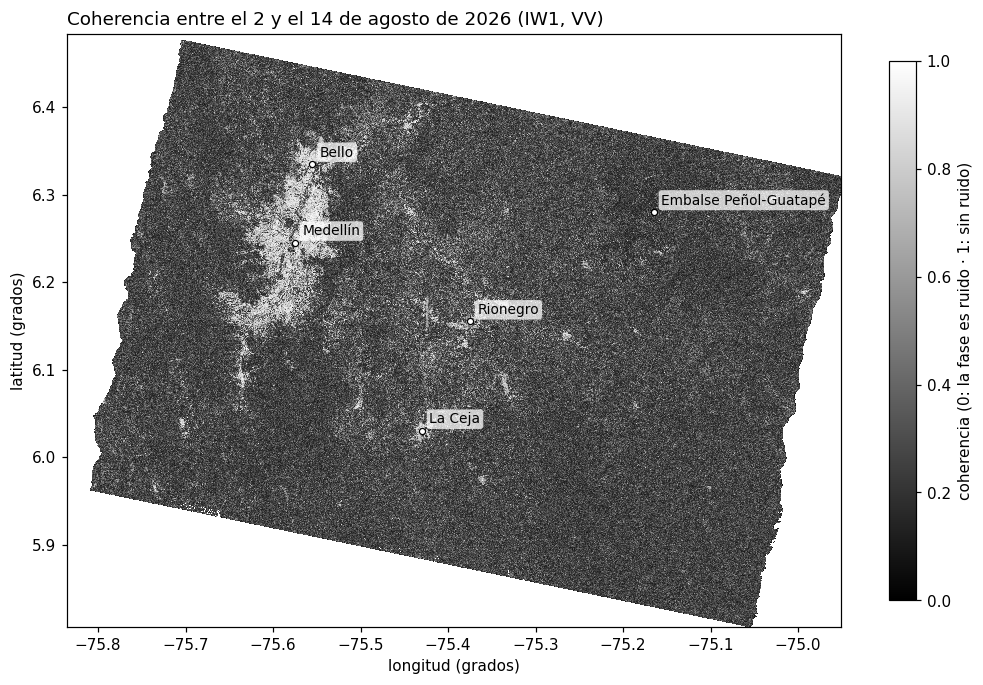

Coherencia media: 0.31 · supera 0,3 el 44% · supera 0,4 el 20%


In [19]:
fig, ax = mapa_base("Coherencia entre el 2 y el 14 de agosto de 2026 (IW1, VV)")
im = ax.imshow(np.where(valido, coh, np.nan), extent=extension, cmap="gray", vmin=0, vmax=1, interpolation="nearest"); lugares(ax)
fig.colorbar(im, ax=ax, shrink=.8, label="coherencia (0: la fase es ruido · 1: sin ruido)"); cerrar(fig, "r1_coherencia.jpg")
print(f"Coherencia media: {coh[valido].mean():.2f} · supera 0,3 el {(coh[valido] > 0.3).mean():.0%} · supera 0,4 el {(coh[valido] > 0.4).mean():.0%}")

Solo las zonas urbanas conservan la coherencia después de 12 días. En el bosque, los cultivos y los embalses la superficie cambia entre una fecha y otra, y la fase deja de ser comparable.

### 6.3 El interferograma filtrado

Cada vuelta completa de color es una franja: 2,77 cm de cambio de distancia en la línea de vista.

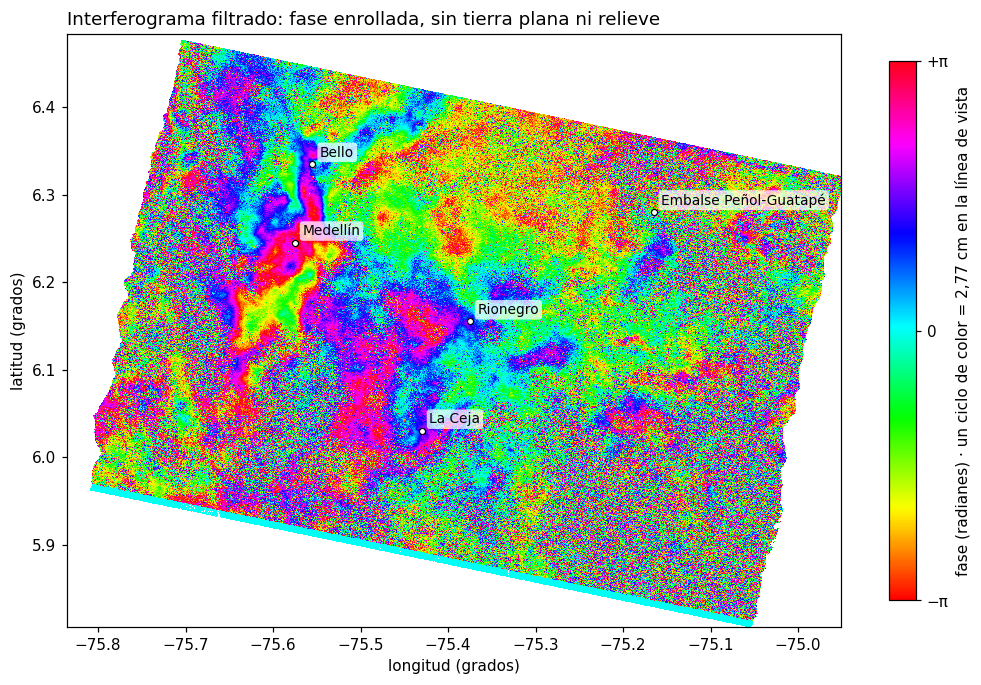

In [20]:
fig, ax = mapa_base("Interferograma filtrado: fase enrollada, sin tierra plana ni relieve")
im = ax.imshow(np.where(valido, fase, np.nan), extent=extension, cmap="hsv", vmin=-np.pi, vmax=np.pi, interpolation="nearest"); lugares(ax)
cb = fig.colorbar(im, ax=ax, shrink=.8, label="fase (radianes) · un ciclo de color = 2,77 cm en la línea de vista")
cb.set_ticks([-np.pi, 0, np.pi]); cb.set_ticklabels(["−π", "0", "+π"]); cerrar(fig, "r2_fase.jpg")

### 6.4 Desplazamiento respecto a Medellín

Primero se dibuja todo el mapa, también donde no hay coherencia; después, solo los píxeles fiables. La diferencia entre los dos mapas es lo que se gana al mirar la coherencia antes de interpretar.

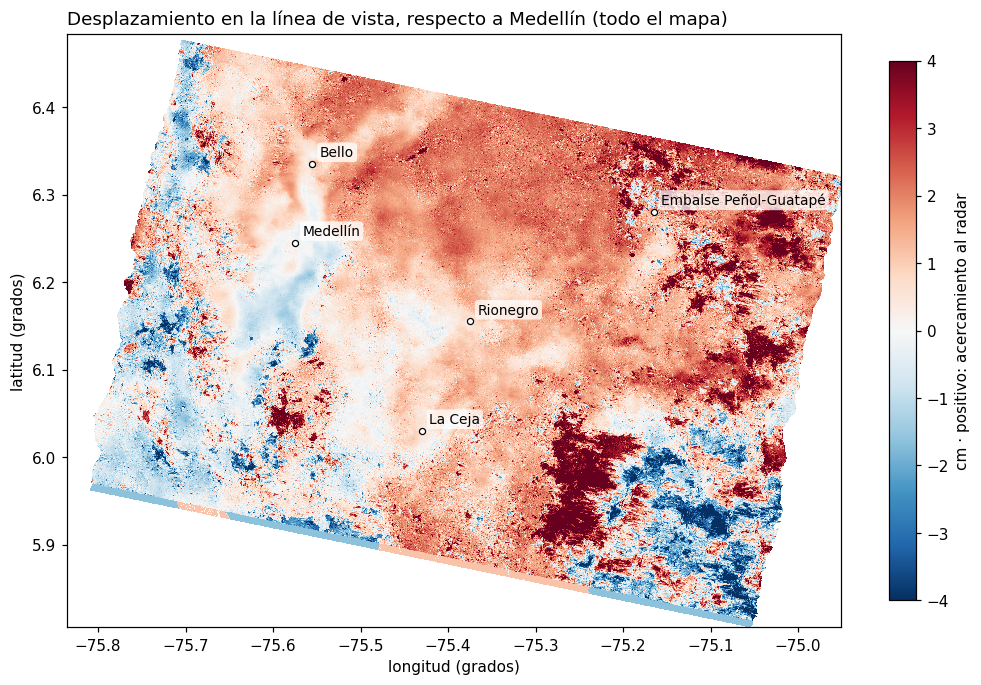

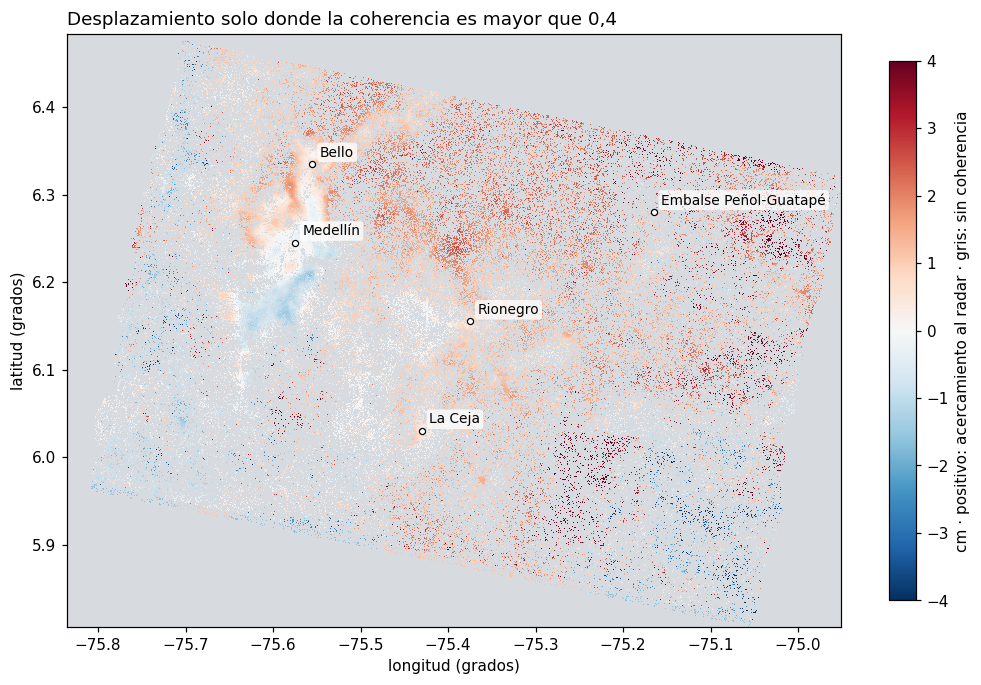

In [21]:
fig, ax = mapa_base("Desplazamiento en la línea de vista, respecto a Medellín (todo el mapa)")
im = ax.imshow(np.where(valido, cm, np.nan), extent=extension, cmap="RdBu_r", vmin=-4, vmax=4, interpolation="nearest"); lugares(ax)
fig.colorbar(im, ax=ax, shrink=.8, label="cm · positivo: acercamiento al radar"); cerrar(fig, "r3_desplazamiento_todo.jpg")

fig, ax = mapa_base("Desplazamiento solo donde la coherencia es mayor que 0,4"); ax.set_facecolor("#d7dbe0")
im = ax.imshow(np.where(fiable, cm, np.nan), extent=extension, cmap="RdBu_r", vmin=-4, vmax=4, interpolation="nearest"); lugares(ax)
fig.colorbar(im, ax=ax, shrink=.8, label="cm · positivo: acercamiento al radar · gris: sin coherencia"); cerrar(fig, "r4_desplazamiento_coherente.jpg")

En el mapa completo, los parches de bordes bruscos al sureste y al occidente son lo que dejan los errores de desenrollado en zonas sin coherencia. En el mapa de píxeles fiables quedan diferencias suaves, de uno a dos centímetros.

### 6.5 ¿Movimiento o atmósfera? Desplazamiento aparente frente a elevación

Si la atmósfera cambió entre las dos fechas, el retraso de la señal depende de cuánta atmósfera cruza, y eso depende de la altitud del terreno. Una relación fuerte entre desplazamiento aparente y elevación delataría ese efecto.

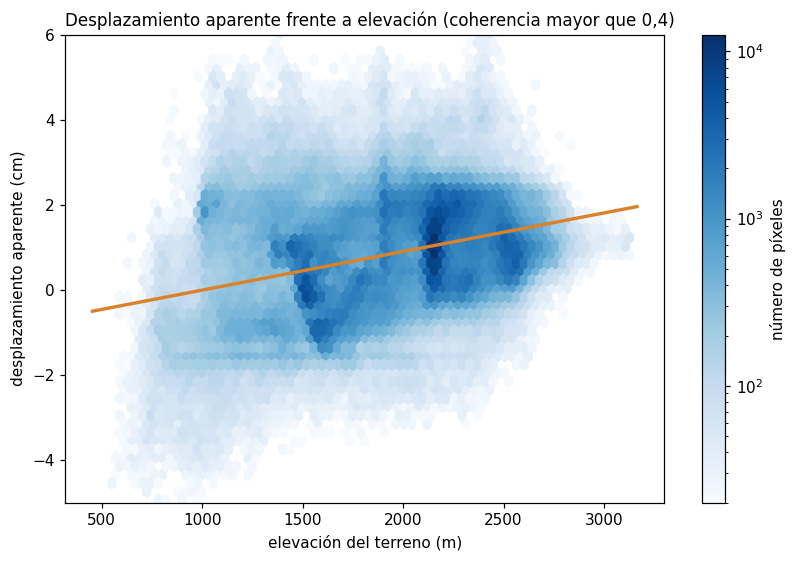

Pendiente: 0.91 cm por kilómetro de altitud · correlación: 0.30
Dispersión: 1.34 cm; al descontar la recta: 1.27 cm
Píxeles excluidos del ajuste por superar 8 cm: 267 · la recta explica el 9% de la variación


In [22]:
x, y = elev[fiable].astype(float), cm[fiable].astype(float); ok = np.isfinite(x) & np.isfinite(y) & (np.abs(y) < 8); excluidos = int((~ok).sum()); x, y = x[ok], y[ok]
recta = np.polyfit(x / 1000, y, 1); r = np.corrcoef(x, y)[0, 1]; resto = y - np.polyval(recta, x / 1000)   # elevación en kilómetros
fig, ax = plt.subplots(figsize=(7.6, 5.2), dpi=110)
hb = ax.hexbin(x, y, gridsize=70, cmap="Blues", mincnt=20, bins="log"); xx = np.array([x.min(), x.max()]); ax.plot(xx, np.polyval(recta, xx / 1000), color="#d9822b", lw=2.2)
ax.set_xlabel("elevación del terreno (m)"); ax.set_ylabel("desplazamiento aparente (cm)"); ax.set_ylim(-5, 6)
ax.set_title("Desplazamiento aparente frente a elevación (coherencia mayor que 0,4)", fontsize=11, loc="left"); fig.colorbar(hb, ax=ax, label="número de píxeles")
cerrar(fig, "r5_elevacion.jpg")
print(f"Pendiente: {recta[0]:.2f} cm por kilómetro de altitud · correlación: {r:.2f}")
print(f"Dispersión: {y.std():.2f} cm; al descontar la recta: {resto.std():.2f} cm")
print(f"Píxeles excluidos del ajuste por superar 8 cm: {excluidos} · la recta explica el {r * r:.0%} de la variación")

La relación existe, pero es débil: la altitud explica muy poco de lo que se ve. Lo que domina son manchas irregulares de decenas de kilómetros.

### 6.6 Cifras por zona

Para cada zona se resume la coherencia, la elevación y el desplazamiento de sus píxeles fiables, siempre respecto a Medellín.

In [23]:
filas = []
for nombre, limites in zonas.items():
    m = caja(*limites) & valido; m4 = m & (coh > 0.4)
    filas.append({"zona": nombre, "coherencia media": round(float(coh[m].mean()), 2), "coherencia > 0,4 (%)": round(100 * m4.sum() / m.sum()), "elevación (m)": round(float(np.median(elev[m]))),
                  "desplazamiento (cm)": round(float(np.median(cm[m4])), 1), "entre (cm)": f"{np.percentile(cm[m4], 10):+.1f} y {np.percentile(cm[m4], 90):+.1f}"})
resumen = pd.DataFrame(filas).set_index("zona"); resumen

,coherencia media,"coherencia > 0,4 (%)",elevación (m),desplazamiento (cm),entre (cm)
zona,,,,,
Medellín,0.61,76,1571,0.0,-0.7 y +0.8
Bello y Copacabana,0.44,47,1629,1.0,+0.4 y +1.9
"Envigado, Itagüí y Sabaneta",0.54,66,1633,-0.9,-1.2 y -0.6
Rionegro,0.38,38,2135,0.8,+0.2 y +1.3
Embalse Peñol-Guatapé,0.27,10,1903,1.7,+0.2 y +3.2
Montaña al occidente del valle,0.29,15,1941,-0.2,-1.9 y +1.8


In [24]:
print(f"Intervalo central del 96 % de los píxeles con coherencia > 0,4: de {np.percentile(y, 2):+.1f} a {np.percentile(y, 98):+.1f} cm · dispersión: {y.std():.1f} cm")
print(f"Píxeles con coherencia > 0,4 a más de una franja (2,77 cm) de Medellín: {(np.abs(y) > 2.77).mean():.1%}")

Intervalo central del 96 % de los píxeles con coherencia > 0,4: de -2.1 a +3.7 cm · dispersión: 1.3 cm
Píxeles con coherencia > 0,4 a más de una franja (2,77 cm) de Medellín: 5.7%


### 6.7 ¿Cuánto depende el resultado del umbral de coherencia?

El umbral de 0,4 es un criterio de este ejercicio, no una regla. Se repiten las cifras principales con 0,3, 0,4 y 0,5 para ver cuánto cambian.

In [25]:
filas = []
for umbral in (0.3, 0.4, 0.5):
    m = valido & (coh > umbral); ref_u = np.median(desp[caja(*zonas["Medellín"]) & m]); c = (desp - ref_u) * 100
    v = c[m].astype(float); v = v[np.abs(v) < 8]
    fila = {"umbral": umbral, "píxeles que pasan (%)": round(100 * m.sum() / valido.sum(), 1), "dispersión (cm)": round(float(v.std()), 2)}
    for nombre in ("Bello y Copacabana", "Envigado, Itagüí y Sabaneta", "Rionegro"):
        fila[nombre + " (cm)"] = round(float(np.median(c[caja(*zonas[nombre]) & m])), 1)
    filas.append(fila)
pd.DataFrame(filas).set_index("umbral")

,píxeles que pasan (%),dispersión (cm),Bello y Copacabana (cm),"Envigado, Itagüí y Sabaneta (cm)",Rionegro (cm)
umbral,,,,,
0.3,43.9,1.50,1.1,-0.9,0.8
0.4,20.0,1.34,1.0,-0.9,0.8
0.5,9.0,1.14,0.9,-0.9,0.8


## 7. Interpretación: qué dice y qué no dice el resultado

Entre las dos fechas ocurrió el sismo del 10 de agosto de 2026: magnitud 7,4, a 103 km de profundidad, con epicentro en San José del Palmar (Chocó), a unos 165 km al suroeste de Medellín (Servicio Geológico Colombiano, comunicado del 10 de agosto de 2026).

- **Lo que el resultado muestra.** Diferencias aparentes de 1 a 2 cm entre zonas vecinas, sin un patrón ordenado. Bello y Envigado, a unos 20 km una de otra, difieren cerca de 2 cm y con signos opuestos.
- **Por qué no se puede atribuir al sismo.** Una señal suya de variación suave podría atenuarse al fijar el cero en Medellín; saber su tamaño aquí exigiría un modelo del sismo o una medida independiente.
- **Lo que es compatible.** Las manchas se parecen a las que deja la atmósfera, y los bordes bruscos en zonas de baja coherencia, a errores de desenrollado. Ninguna de las dos cosas queda demostrada con este par: la relación con la altitud solo explica una décima parte de la variación.
- **Una cifra para tratar con cuidado.** El valor del embalse Peñol-Guatapé sale de los pocos píxeles que pasan el umbral; antes de leerlo como movimiento habría que comprobar si caen sobre agua, orillas o construcciones.
- **Qué haría falta.** Otro par sin sismo para comparar, varias fechas para promediar la atmósfera, la órbita ascendente y una estación GNSS de la zona como control.

La conclusión proporcional a la evidencia: hay una señal aparente de 1 a 2 cm cuya causa queda abierta. Lo que sí deja claro el ejercicio es el orden de lectura de todo interferograma: primero la coherencia, después la zona de referencia y solo al final los centímetros.